<h1 style="
background:linear-gradient(to right,#2193b0,#1c1a99);
color:white;
padding:20px;
border-radius:12px;
text-align:center;">
DIABETES PREDICTION USING MACHINE LEARNING
</h1>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
df = pd.read_csv("diabetes_dataset_400-1.csv")
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0           10       98             51             27      140  24.0   
1            8       92             87             37       31  18.8   
2            9       76             85             22      294  29.3   
3            0      110             94             37      189  25.5   
4            5       96             55             34       64  27.7   

   DiabetesPedigreeFunction  Age  Outcome  
0                      1.87   64        1  
1                      0.62   53        0  
2                      1.18   38        0  
3                      0.62   69        0  
4                      0.93   37        0  


In [4]:
#EXPORE THE DATA
print(df.info())
print(df.describe())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               400 non-null    int64  
 1   Glucose                   400 non-null    int64  
 2   BloodPressure             400 non-null    int64  
 3   SkinThickness             400 non-null    int64  
 4   Insulin                   400 non-null    int64  
 5   BMI                       400 non-null    float64
 6   DiabetesPedigreeFunction  400 non-null    float64
 7   Age                       400 non-null    int64  
 8   Outcome                   400 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 28.3 KB
None
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count    400.00000  400.000000     400.000000     400.000000  400.000000   
mean       5.28250  135.530000      75.320000      30.452500  154.620000   
std    

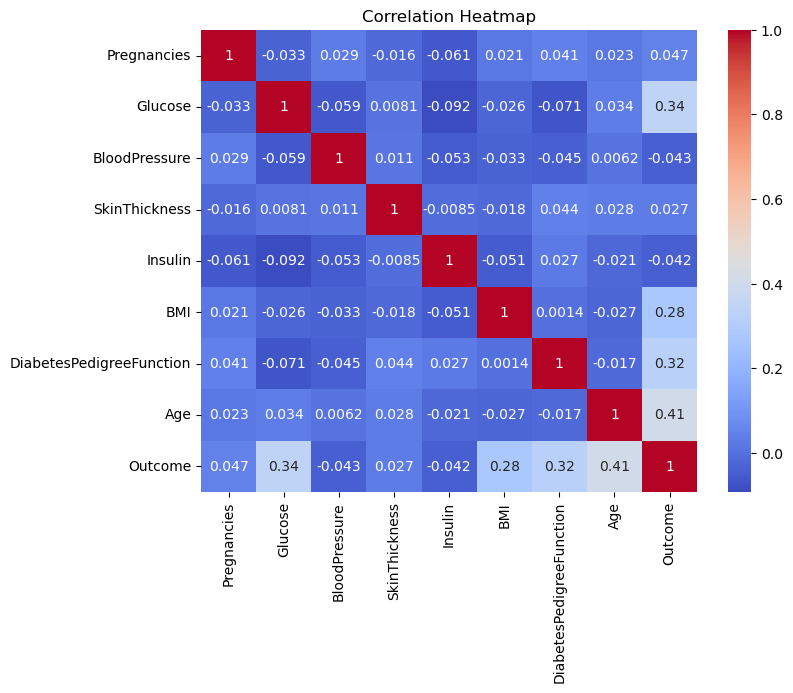

In [5]:
# CORRELATION HEATMAP
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

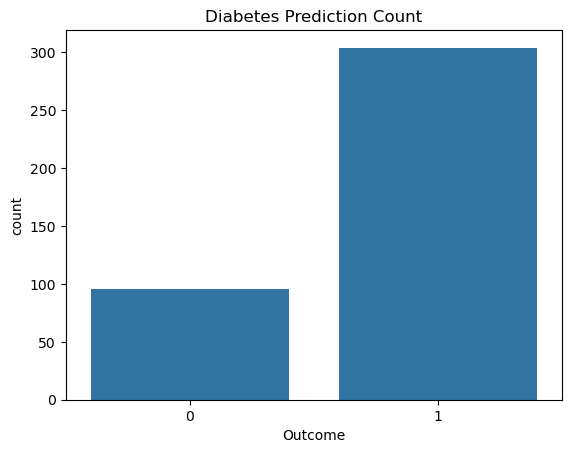

In [6]:
#DIABETES DISTRIBUTION
sns.countplot(x="Outcome", data=df)
plt.title("Diabetes Prediction Count")
plt.show()

In [7]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
#FEATURE SCALING
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
model = LogisticRegression()

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [11]:
y_pred = model.predict(X_test)

In [12]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9


In [13]:
#CONFUSSION MATRIX
cm = confusion_matrix(y_test, y_pred)
print(cm)


[[18  4]
 [ 4 54]]


In [14]:
#CLASSIFICATION REPORT
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.82      0.82        22
           1       0.93      0.93      0.93        58

    accuracy                           0.90        80
   macro avg       0.87      0.87      0.87        80
weighted avg       0.90      0.90      0.90        80



In [15]:
#SAMPLE PREDICTIOn
# Take input from the user
pregnancies = int(input("Enter Pregnancies: "))
glucose = float(input("Enter Glucose: "))
blood_pressure = float(input("Enter Blood Pressure: "))
skin_thickness = float(input("Enter Skin Thickness: "))
insulin = float(input("Enter Insulin: "))
bmi = float(input("Enter BMI: "))
diabetes_pedigree = float(input("Enter Diabetes Pedigree Function: "))
age = int(input("Enter Age: "))

# Create DataFrame
sample = pd.DataFrame({
    "Pregnancies": [pregnancies],
    "Glucose": [glucose],
    "BloodPressure": [blood_pressure],
    "SkinThickness": [skin_thickness],
    "Insulin": [insulin],
    "BMI": [bmi],
    "DiabetesPedigreeFunction": [diabetes_pedigree],
    "Age": [age]
})

sample_scaled = scaler.transform(sample)

# Predict
prediction = model.predict(sample_scaled)

if prediction[0] == 1:
    print("The person is Diabetic")
else:
    print("The person is Not Diabetic")

Enter Pregnancies:  2
Enter Glucose:  145
Enter Blood Pressure:  78
Enter Skin Thickness:  30
Enter Insulin:  150
Enter BMI:  32.5
Enter Diabetes Pedigree Function:  .62
Enter Age:  45


The person is Diabetic
